<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Pratical8_by_Tushar_Guleria(GF202459441).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 8 : Decision Tree Classifier
Step 1: Importing Required Libraries
In this step, we import the Python libraries required to perform the Decision Tree classification. Pandas is used to load and manipulate the dataset, NumPy supports numerical operations, and Matplotlib is used to create visualizations. Scikit-learn provides the functions required to split the dataset, build the Decision Tree classifier, visualize the tree, and evaluate the model's performance.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Step 2: Loading the Dataset
In this step, we load the Pima Indians Diabetes dataset from a CSV file using Pandas. The dataset contains medical measurements that will be used to predict whether a patient has diabetes. The loaded data is stored in a DataFrame named df, which allows us to inspect and process the dataset using Pandas functions.


In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Step 3: Exploring the Dataset
Before building a machine-learning model, it is important to understand the structure and contents of the dataset. We use shape to find the number of rows and columns, columns to view the feature names, info() to inspect data types and non-null counts, and describe() to obtain summary statistics such as mean, standard deviation, minimum, and maximum.

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
df.describe()

Dataset shape: (768, 9)

Column names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summa

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Step 4: Feature Selection - Independent and Dependent Variables
In this step, we separate the dataset into independent variables (features) and a dependent variable (target).

In [ ]:
# Independent variables (features)
X = df.drop("Outcome", axis = 1)
# Dependent variable (target)
y = df["Outcome"]
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (768, 8)
Target shape: (768,)

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


Step 5: Splitting the Dataset
In this step, we divide the dataset into training and testing sets using the train_test_split() function from Scikit-learn. The training set (80%) is used by the model to learn patterns from the data, while the testing set (20%) is used to evaluate how well the trained model predicts outcomes on data it has not seen during training. The random_state=42 parameter makes the split reproducible, and stratify=y preserves the proportion of each target class

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (614, 8)
Testing features: (154, 8)
Training targets: (614,)
Testing targets: (154,)


Step 6: Building the Decision Tree Classifier
In this step, we create and train a Decision Tree Classifier using Scikit-learn. We use criterion="entropy" to select splits based on entropy and information gain, which measures how much uncertainty decreases after a split. We set max_depth = 3 to limit the tree's depth, making it easier to visualize and understand.

In [ ]:
# Create the Decision Tree Classifier
dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth = 3,
    random_state = 42
)
# Train the model
dt.fit(X_train, y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Text Cell 7
Step 7: Model Prediction and Evaluation
After training the model, we use the testing dataset to predict the target variable. We evaluate the model using accuracy, a confusion matrix to show correct and incorrect predictions, and a classification report displaying precision, recall, and F1-score.

In [ ]:
# Predict outcomes using the testing data
y_pred = dt.predict(X_test)
# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division = 0
))

Accuracy: 0.6948051948051948

Confusion Matrix:
[[92  8]
 [39 15]]

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.70      0.92      0.80       100
    Diabetes       0.65      0.28      0.39        54

    accuracy                           0.69       154
   macro avg       0.68      0.60      0.59       154
weighted avg       0.68      0.69      0.65       154



Step 8: Decision Tree Visualization
In this step, we visualize the trained Decision Tree using Matplotlib and Scikit-learn's plot_tree() function. The visualization displays the feature used at each split, the decision threshold, the number of samples, and the class distribution.

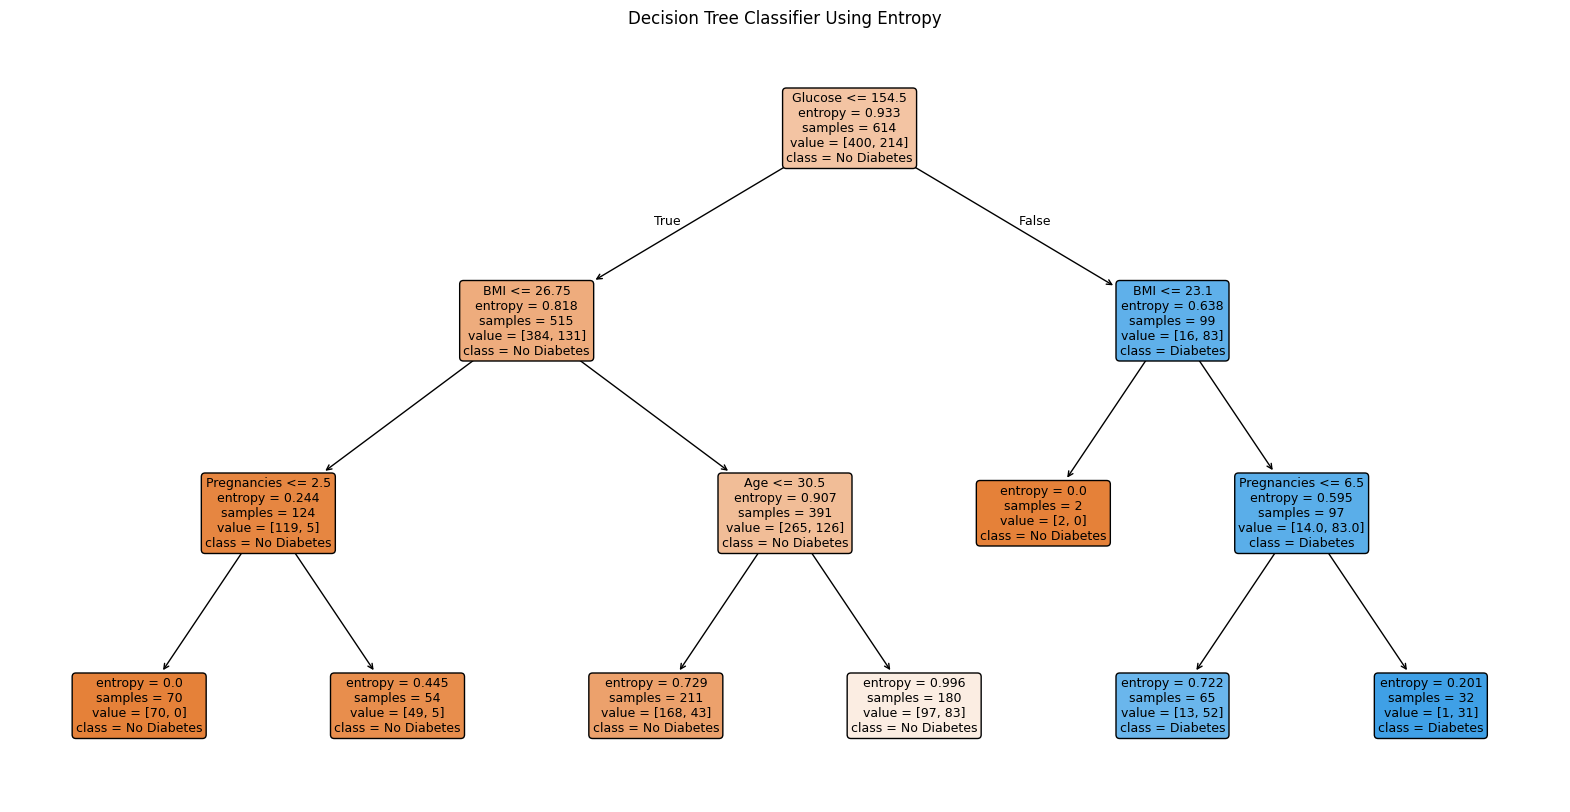

In [ ]:
plt.figure(figsize =(20,10))
plot_tree(
    dt,
    feature_names = X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize = 9
)
plt.title("Decision Tree Classifier Using Entropy")
plt.show()

Step 9: Identifying the Root Node
The root node is the first and topmost node of a Decision Tree, representing the first feature used to split the dataset. Because our model uses entropy, it searches for a split that provides high information gain.


In [ ]:
# Identify the root feature
root_index = dt.tree_.feature[0]
root_threshold = dt.tree_.threshold[0]
if root_index >= 0:
    root_feature = X.columns[root_index]
    print("Root feature:", root_feature)
    print("Root threshold:", root_threshold)
    print(
        f"Root decision: {root_feature} <= "
        f"{root_threshold:.2f}"
    )
else:
    print("The root node is a leaf node.")

Root feature: Glucose
Root threshold: 154.5
Root decision: Glucose <= 154.50


Text Cell 10
Step 10: Entropy, Information Gain, and Gini Index
Entropy measures the uncertainty or impurity of the target classes. Information Gain measures the reduction in entropy after splitting the dataset into child nodes. The Gini Index is another measure of impurity. We calculate these metrics to help explain the quality of the selected split.

In [ ]:
# Functions to calculate entropy and Gini impurity
def calculate_entropy(target):
    probabilities = target.value_counts(normalize=True)
    return -np.sum(
        probabilities * np.log2(probabilities)
    )

def calculate_gini(target):
    probabilities = target.value_counts(normalize=True)
    return 1 - np.sum(probabilities ** 2)

# Split the training data using the actual root rule
left_mask = X_train[root_feature] <= root_threshold
y_left = y_train[left_mask]
y_right = y_train[~left_mask]

# Parent and child entropy
parent_entropy = calculate_entropy(y_train)
left_entropy = calculate_entropy(y_left)
right_entropy = calculate_entropy(y_right)

# Weighted entropy of the child nodes
n = len(y_train)
weighted_child_entropy = (
    len(y_left) / n * left_entropy
    + len(y_right) / n * right_entropy
)

# Information Gain
information_gain = parent_entropy - weighted_child_entropy

# Parent and child Gini Index
parent_gini = calculate_gini(y_train)
left_gini = calculate_gini(y_left)
right_gini = calculate_gini(y_right)
weighted_child_gini = (
    len(y_left) / n * left_gini
    + len(y_right) / n * right_gini
)

print("Root feature:", root_feature)
print("Root threshold:", round(root_threshold, 4))
print("\n--- Entropy Calculations ---")
print("Parent Entropy:", round(parent_entropy, 4))
print("Left Child Entropy:", round(left_entropy, 4))
print("Right Child Entropy:", round(right_entropy, 4))
print("Weighted Child Entropy:", round(weighted_child_entropy, 4))
print("Information Gain:", round(information_gain, 4))
print("\n--- Gini Calculations ---")
print("Parent Gini Index:", round(parent_gini, 4))
print("Left Child Gini Index:", round(left_gini, 4))
print("Right Child Gini Index:", round(right_gini, 4))
print("Weighted Child Gini Index:", round(weighted_child_gini, 4))
print(
    "Gini Reduction:",
    round(parent_gini - weighted_child_gini, 4)
)

Root feature: Glucose
Root threshold: 154.5

--- Entropy Calculations ---
Parent Entropy: 0.9328
Left Child Entropy: 0.8181
Right Child Entropy: 0.6382
Weighted Child Entropy: 0.7891
Information Gain: 0.1436

--- Gini Calculations ---
Parent Gini Index: 0.4541
Left Child Gini Index: 0.3793
Right Child Gini Index: 0.271
Weighted Child Gini Index: 0.3619
Gini Reduction: 0.0923


Step 13: Comparing Candidate Root Splits
A decision tree using entropy selects a split that maximizes information gain. To investigate the root selection, we compare the best information gain obtainable from different features in the training data by evaluating possible thresholds for each feature.

In [ ]:
def best_entropy_split(feature_values, target):
    data = pd.DataFrame({
        "feature": feature_values,
        "target": target
    }).sort_values("feature")

    values = data["feature"].to_numpy()
    labels = data["target"].to_numpy()

    parent_entropy = calculate_entropy(pd.Series(labels))
    best_gain = -1
    best_threshold = None

    # Consider midpoints between distinct feature values
    candidates = np.where(values[:-1] != values[1:])[0]

    for i in candidates:
        threshold = (values[i] + values[i + 1]) / 2

        left = values <= threshold
        y_left = pd.Series(labels[left])
        y_right = pd.Series(labels[~left])

        weighted_entropy = (
            len(y_left) / len(labels) * calculate_entropy(y_left)
            + len(y_right) / len(labels) * calculate_entropy(y_right)
        )

        gain = parent_entropy - weighted_entropy

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_threshold, best_gain

results = []
for feature in X_train.columns:
    threshold, gain = best_entropy_split(
        X_train[feature],
        y_train
    )
    results.append({
        "Feature": feature,
        "Best Threshold": threshold,
        "Information Gain": gain
    })

comparison = pd.DataFrame(results).sort_values(
    "Information Gain",
    ascending=False
)
print(comparison.to_string(index=False))

                 Feature  Best Threshold  Information Gain
                 Glucose        154.5000          0.143640
                     BMI         29.6500          0.074059
                     Age         27.5000          0.065433
             Pregnancies          6.5000          0.038768
                 Insulin        128.5000          0.036772
DiabetesPedigreeFunction          0.5275          0.024315
           SkinThickness         32.5000          0.022859
           BloodPressure         69.0000          0.018507


Conclusion
This practical demonstrated a complete Decision Tree classification workflow using the Pima Indians Diabetes dataset: feature selection, dataset splitting, model evaluation, visualization, and the use of entropy, information gain, and Gini impurity to analyze splits. The model selected Glucose as the root feature with a threshold of 154.5, which reduced entropy by an information gain of 0.1436. This model is for educational purposes only and should not be used to make medical decisions.